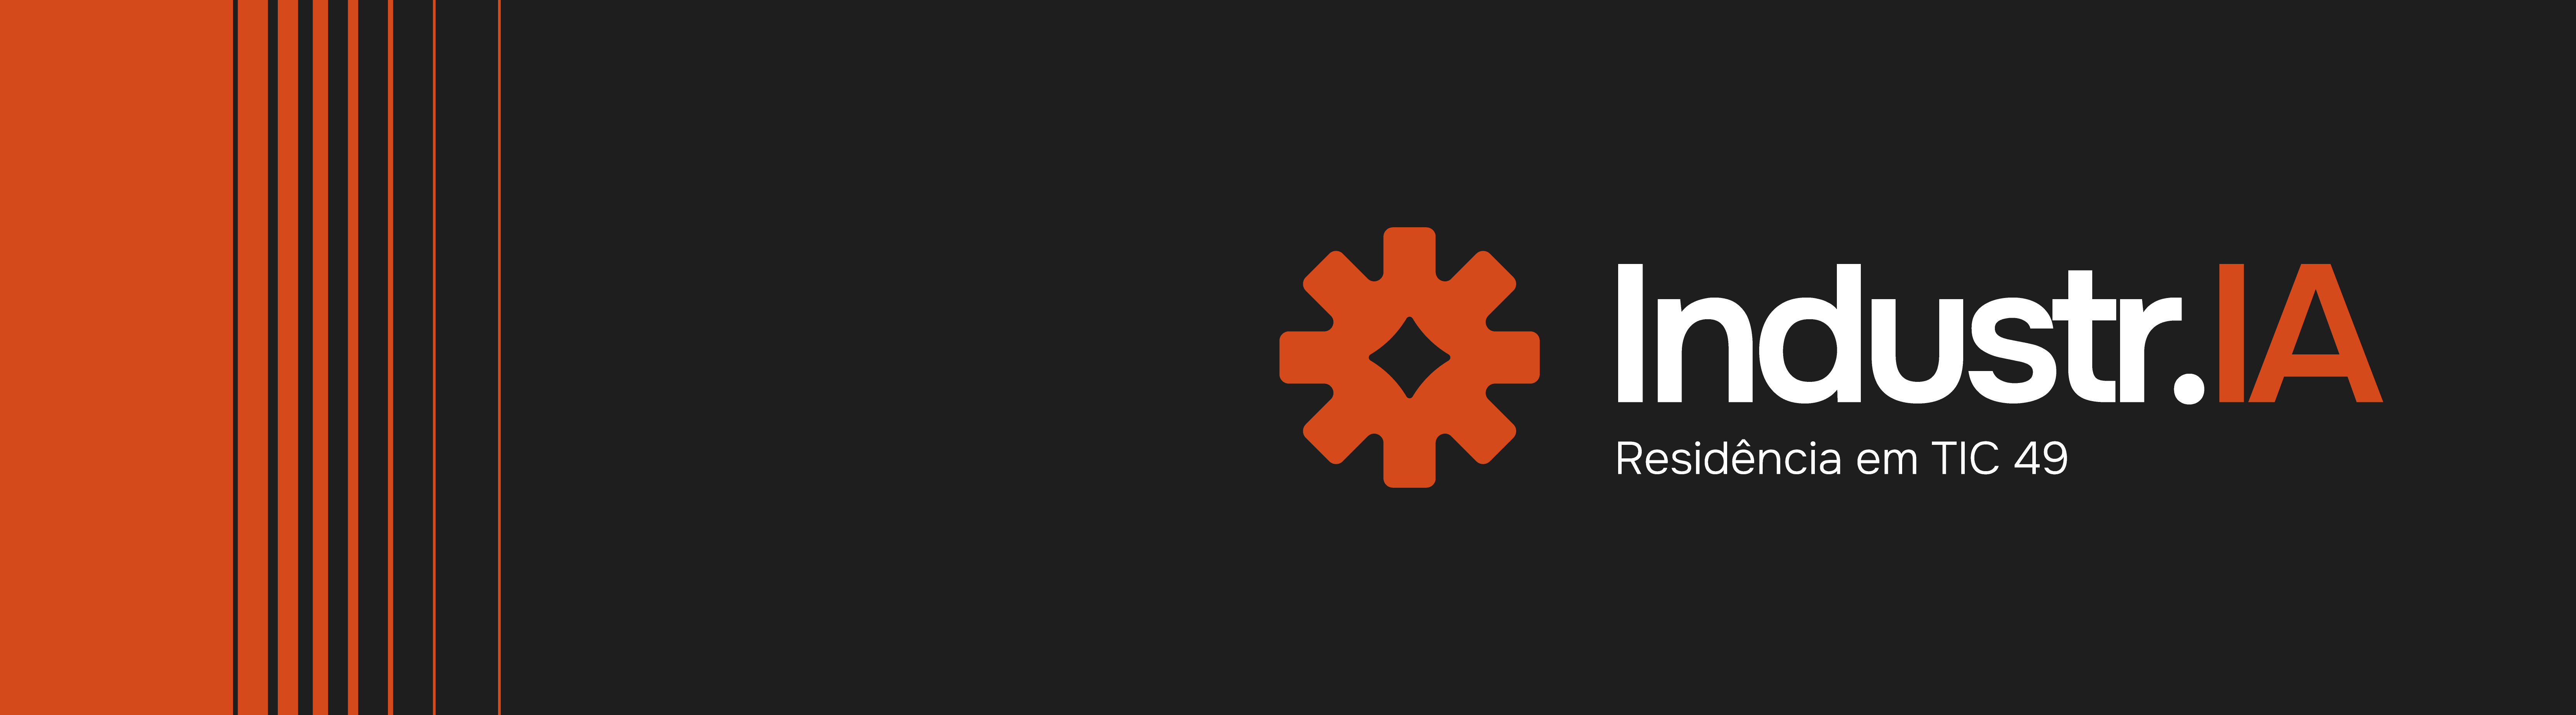

# 🤖 Fundamentos de IA Aplicada

## Módulo M2, IA Agêntica, lente da autonomia

### Competência M2.C1
**Descrever os componentes canônicos de um agente e diferenciá-lo de um assistente conversacional, reconhecendo os padrões aplicados centrais em PD&I industrial.**

---

## 📋 Sobre este notebook

Este notebook é **demonstrativo** e foi projetado para ser executado do início ao fim sem necessidade de intervenção.

No **Google Colab**:

1. Selecione um ambiente de execução **CPU** (GPU não é necessária).
2. Acesse **Ambiente de execução → Executar tudo**.
3. Acompanhe as saídas na ordem em que aparecem.

✅ Não há download de modelos.  
✅ Não é necessária nenhuma chave de API.  
✅ Não é necessário contratar serviços pagos.

O notebook usa apenas a biblioteca padrão do Python e roda em segundos.

> ℹ️ Uma escolha de projeto importante: para que o notebook rode em qualquer ambiente, de forma gratuita, sem GPU e de modo determinístico, o **reasoning engine** aqui é uma função de decisão transparente, escrita em Python, que você pode ler por inteiro. Em produção, esse papel seria desempenhado por um modelo de linguagem. O foco deste notebook é a **estrutura do laço**, o **contrato de tool calling** e o **trace**, e não a capacidade do modelo.

---

## 🎯 Objetivo

A pergunta central deste notebook é:

> **Dado um objetivo, como um agente decide a próxima ação, executa uma ferramenta e usa o resultado para decidir o passo seguinte?**

E, mais importante:

> **O que o trace dessa sequência revela sobre o comportamento do agente, inclusive quando ele seleciona a ferramenta errada?**

Ao longo do notebook, você vai construir um agente mínimo com duas ferramentas e analisar:

- 🔁 O ciclo **perceber, decidir e agir**;
- 🧰 O **contrato de tool calling** entre o agente e o ambiente;
- 🧾 O **trace** como artefato de auditoria;
- ⚠️ Uma seleção de ferramenta **correta** e uma **incorreta**.

---

## 🔍 O que observar durante a execução

Enquanto acompanha os exemplos, procure identificar:

- Qual é o **objetivo** dado ao agente;
- Qual **ferramenta** o agente seleciona em cada passo, e por quê;
- O que a **observação** retornada pelo ambiente muda na decisão seguinte;
- Em que passo a seleção de ferramenta é **adequada** e em que passo é **inadequada**;
- Qual **condição de parada** encerra o laço.

> 🚀 Ao final, há uma seção de **perguntas para reflexão** que conecta o notebook ao próximo e-book. Nada ali é obrigatório para a compreensão do conteúdo principal.

## 🎯 Objetivos de aprendizagem

Ao acompanhar este notebook, procure observar quatro aspectos:

1. Os **componentes canônicos** de um agente, identificando no código o **reasoning engine**, as **tools** e o **laço** (consulte o glossário GLO-M2).
2. O **contrato de tool calling**, ou seja, como uma decisão vira uma chamada estruturada, validada e executada pelo ambiente.
3. O papel do **trace** na leitura do comportamento do agente, incluindo o reconhecimento de uma seleção de ferramenta **correta** e de uma **incorreta**.
4. A diferença entre **decidir o caminho de antemão** e **deixar o sistema decidir o caminho em execução**, e o que isso sugere sobre custo e previsibilidade.

---

## 📚 Vocabulário utilizado

Os seguintes termos aparecem ao longo do notebook e estão definidos no glossário do módulo:

- agente
- assistente conversacional
- reasoning engine
- tool
- tool calling
- observação
- laço (perceber, decidir, agir)
- condição de parada
- trace
- workflow determinista

> Se algum termo parecer novo ou pouco familiar, consulte o glossário (GLO-M2) antes de prosseguir.

## 1. Preparação

Neste notebook usamos apenas a biblioteca padrão do Python, sem dependências externas:

In [ ]:
import ast
import json
import operator
import re

## 2. Corpus mock

O agente consulta uma pequena base de cinco documentos técnicos sobre um mesmo equipamento (um mancal), embutida no notebook para mantê-lo autocontido e determinístico.

Para cada pergunta, apenas um documento é relevante. Os demais funcionam como distratores: numa pergunta sobre torque, por exemplo, o documento de torque é o relevante, e os de temperatura, manutenção, lubrificação e vibração são distratores. A ferramenta de busca retorna os dois trechos de maior sobreposição de palavras com a consulta, de modo que um distrator pode vir ao lado do documento relevante. Mais adiante, o reasoning engine lida com isso usando apenas o trecho mais relevante, e você verá esse efeito no trace da segunda tarefa.

In [ ]:
CORPUS = {
    "doc_torque": "Parafuso de fixacao do mancal: torque nominal de 50 N.m, "
                  "com tolerancia de mais ou menos 5 por cento.",
    "doc_temperatura": "Faixa de temperatura de operacao do mancal: de 40 a 80 graus C.",
    "doc_manutencao": "Intervalo de manutencao preventiva do mancal: a cada 2000 horas de operacao.",
    "doc_lubrificacao": "Lubrificacao do mancal: graxa de litio, reaplicar a cada 500 horas.",
    "doc_vibracao": "Limite de vibracao aceitavel do mancal: ate 4.5 mm por segundo em RMS.",
}

## 3. Ferramentas e o contrato de tool calling

Cada ferramenta tem um contrato explícito: nome, descrição e parâmetros esperados. O reasoning engine apenas propõe a chamada; quem executa e valida é o código ao redor (a função executar_tool). É esse ponto, em que a decisão vira efeito, que concentra a validação e o tratamento de erro.

In [ ]:
CONTRATOS_TOOLS = [
    {
        "nome": "buscar_corpus",
        "descricao": "Busca trechos na base de documentos tecnicos do equipamento.",
        "parametros": {"consulta": "texto com os termos a procurar"},
    },
    {
        "nome": "calcular",
        "descricao": "Avalia uma expressao aritmetica simples e retorna o resultado numerico.",
        "parametros": {"expressao": "expressao apenas com numeros e operadores + - * / ( )"},
    },
]

_OPERADORES = {
    ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul,
    ast.Div: operator.truediv, ast.USub: operator.neg, ast.UAdd: operator.pos,
}


def _avaliar_no(no):
    if isinstance(no, ast.Constant) and isinstance(no.value, (int, float)):
        return no.value
    if isinstance(no, ast.BinOp) and type(no.op) in _OPERADORES:
        return _OPERADORES[type(no.op)](_avaliar_no(no.left), _avaliar_no(no.right))
    if isinstance(no, ast.UnaryOp) and type(no.op) in _OPERADORES:
        return _OPERADORES[type(no.op)](_avaliar_no(no.operand))
    raise ValueError("expressao contem elemento nao permitido")


def calcular(expressao):
    """Calculadora controlada: aceita apenas aritmetica com numeros."""
    if not re.fullmatch(r"[0-9eE+\-*/(). ]+", expressao or ""):
        termos = re.findall(r"[A-Za-z_]+", expressao or "")
        termo = termos[0] if termos else "desconhecido"
        return {"ok": False, "erro": f"expressao contem termo nao numerico: {termo}"}
    try:
        arvore = ast.parse(expressao, mode="eval")
        valor = _avaliar_no(arvore.body)
        return {"ok": True, "resultado": round(float(valor), 4)}
    except Exception as exc:
        return {"ok": False, "erro": f"expressao invalida ({exc})"}


def buscar_corpus(consulta):
    """Busca por sobreposicao de palavras entre a consulta e cada documento."""
    termos = set(re.findall(r"[a-z0-9]+", (consulta or "").lower()))
    achados = []
    for doc_id, texto in CORPUS.items():
        palavras = set(re.findall(r"[a-z0-9]+", texto.lower()))
        pontuacao = len(termos & palavras)
        if pontuacao > 0:
            achados.append((pontuacao, doc_id, texto))
    achados.sort(reverse=True)
    if not achados:
        return {"ok": True, "trechos": [], "aviso": "nenhum trecho encontrado"}
    return {"ok": True, "trechos": [{"doc": d, "texto": t} for _, d, t in achados[:2]]}


REGISTRO_TOOLS = {"buscar_corpus": buscar_corpus, "calcular": calcular}


def executar_tool(nome, argumentos):
    """Despacha a chamada de ferramenta, validando o contrato antes de executar."""
    if nome not in REGISTRO_TOOLS:
        return {"ok": False, "erro": f"ferramenta desconhecida: {nome}"}
    esperado = next(c["parametros"] for c in CONTRATOS_TOOLS if c["nome"] == nome)
    faltando = [p for p in esperado if p not in argumentos]
    if faltando:
        return {"ok": False, "erro": f"argumentos faltando: {', '.join(faltando)}"}
    return REGISTRO_TOOLS[nome](**{p: argumentos[p] for p in esperado})

## 4. Leitura do estado

Funções auxiliares que o reasoning engine usa para ler o estado da tarefa: o que já foi buscado, o que já foi calculado, se houve erro, e quais números e trechos foram recuperados.

In [ ]:
def _numeros(texto):
    return [float(n) for n in re.findall(r"-?\d+(?:\.\d+)?", texto or "")]


def _ja_executou(historico, nome, com_sucesso=True):
    for passo in historico:
        if passo["acao"] == nome and (not com_sucesso or passo["observacao"].get("ok")):
            if not com_sucesso:
                return True
            obs = passo["observacao"]
            if nome == "buscar_corpus" and obs.get("trechos"):
                return True
            if nome == "calcular" and "resultado" in obs:
                return True
    return False


def _houve_erro(historico, nome):
    return any(p["acao"] == nome and not p["observacao"].get("ok") for p in historico)


def _texto_trecho_principal(historico):
    # Usa apenas o trecho mais relevante (o primeiro retornado pela busca),
    # ignorando documentos distratores que tambem voltaram na observacao.
    for passo in historico:
        if passo["acao"] == "buscar_corpus":
            trechos = passo["observacao"].get("trechos", [])
            if trechos:
                return trechos[0]["texto"]
    return ""


def _resultados_calculo(historico):
    return [p["observacao"]["resultado"] for p in historico
            if p["acao"] == "calcular" and p["observacao"].get("ok")]

## 5. Reasoning engine

Esta é a função de decisão do agente: dado o objetivo e o histórico de observações, ela decide a próxima ação, uma chamada de ferramenta ou a resposta final. É uma heurística legível, que faz o papel que um modelo de linguagem teria em produção.

Repare na primeira regra: quando o objetivo fala em margem ou diferença, o motor tende a ir direto para a calculadora, antes de buscar os dados. Isso é deliberado, e modela uma falha comum de agentes na prática, agir antes de coletar a informação necessária. Depois do erro, o motor se corrige. Guarde esse ponto para a leitura do trace.

In [ ]:
def _pede_conta(objetivo):
    chaves = ("margem", "quantos", "diferenca", "acima", "abaixo", "dentro", "tolerancia")
    return any(c in objetivo.lower() for c in chaves)


def _termos_busca(objetivo):
    obj = objetivo.lower()
    if "torque" in obj:
        return "torque parafuso mancal tolerancia"
    if "temperatura" in obj or "graus" in obj:
        return "temperatura operacao mancal faixa"
    if "vibracao" in obj:
        return "vibracao mancal limite"
    return "mancal especificacao"


def _montar_expressao(objetivo, historico):
    texto = _texto_trecho_principal(historico)
    nums = _numeros(texto)
    obj = objetivo.lower()
    if "tolerancia" in obj or "dentro" in obj:
        nominal = nums[0] if nums else 0
        pct = nums[1] if len(nums) > 1 else 0
        return f"{nominal} - {nominal} * {pct} / 100"
    if "margem" in obj or "acima" in obj or "diferenca" in obj:
        leitura = _numeros(objetivo)
        nums_ord = sorted(nums)
        limite_sup = nums_ord[-1] if nums_ord else 0
        leitura_v = leitura[0] if leitura else 0
        return f"{int(leitura_v)} - {int(limite_sup)}"
    return "0"


def _redigir_resposta(objetivo, historico):
    texto = _texto_trecho_principal(historico)
    nums_doc = _numeros(texto)
    calc = _resultados_calculo(historico)
    obj = objetivo.lower()
    leitura = _numeros(objetivo)
    if "tolerancia" in obj or "dentro" in obj:
        nominal = nums_doc[0] if nums_doc else 0
        pct = nums_doc[1] if len(nums_doc) > 1 else 0
        inferior = calc[0] if calc else nominal
        superior = round(nominal + nominal * pct / 100, 4)
        medido = leitura[0] if leitura else 0
        dentro = inferior <= medido <= superior
        situacao = "dentro" if dentro else "fora"
        return (f"O valor medido de {medido:g} N.m esta {situacao} da tolerancia. "
                f"A faixa permitida vai de {inferior:g} a {superior:g} N.m "
                f"(nominal {nominal:g} N.m, tolerancia de {pct:g} por cento).")
    if "margem" in obj or "acima" in obj or "diferenca" in obj:
        nums_ord = sorted(nums_doc)
        limite_inf = nums_ord[0] if nums_ord else 0
        limite_sup = nums_ord[-1] if nums_ord else 0
        leitura_v = leitura[0] if leitura else 0
        margem = calc[-1] if calc else (leitura_v - limite_sup)
        if margem > 0:
            return (f"A faixa de operacao vai de {limite_inf:g} a {limite_sup:g} graus. "
                    f"A leitura de {leitura_v:g} graus esta {margem:g} graus acima do limite "
                    f"superior, portanto fora da faixa.")
        return (f"A faixa de operacao vai de {limite_inf:g} a {limite_sup:g} graus. "
                f"A leitura de {leitura_v:g} graus esta dentro da faixa.")
    return "Nao foi possivel concluir com a informacao disponivel."


def decidir_proxima_acao(objetivo, historico):
    obj = objetivo.lower()
    ja_buscou = _ja_executou(historico, "buscar_corpus")
    ja_calculou = _ja_executou(historico, "calcular")
    erro_calculo = _houve_erro(historico, "calcular")

    # Heuristica deliberadamente imperfeita: quando o objetivo menciona margem
    # ou diferenca, o motor pula direto para a calculadora, antes de buscar os
    # dados. Modela uma falha comum: agir antes de coletar a informacao.
    if ("margem" in obj or "diferenca" in obj) and not ja_buscou and not erro_calculo:
        leitura = _numeros(objetivo)
        leitura_txt = str(int(leitura[0])) if leitura else "leitura"
        return {
            "raciocinio": "O objetivo pede uma margem, entao vou calcular a diferenca "
                          "em relacao ao limite. Tentativa direta, ainda sem buscar o limite.",
            "acao": "calcular",
            "argumentos": {"expressao": f"{leitura_txt} - limite_superior"},
        }

    if not ja_buscou:
        return {
            "raciocinio": "Ainda nao tenho a especificacao do equipamento. Vou buscar no corpus.",
            "acao": "buscar_corpus",
            "argumentos": {"consulta": _termos_busca(objetivo)},
        }

    if _pede_conta(objetivo) and not ja_calculou:
        return {
            "raciocinio": "Ja tenho os valores da especificacao. Vou calcular para comparar.",
            "acao": "calcular",
            "argumentos": {"expressao": _montar_expressao(objetivo, historico)},
        }

    return {
        "raciocinio": "Tenho informacao e calculo suficientes. Vou redigir a resposta final.",
        "acao": "FINAL",
        "argumentos": {"resposta": _redigir_resposta(objetivo, historico)},
    }

## 6. O laço do agente

O laço implementa o ciclo perceber, decidir, agir, com duas condições de parada explícitas: o motor declara a resposta final, ou o número de iterações atinge o teto. A cada passo, registramos o trace: o raciocínio, a ação, os argumentos e a observação retornada.

In [ ]:
def executar_agente(objetivo, max_iteracoes=6):
    historico = []
    for i in range(1, max_iteracoes + 1):
        decisao = decidir_proxima_acao(objetivo, historico)
        if decisao["acao"] == "FINAL":
            return {"resposta": decisao["argumentos"]["resposta"],
                    "trace": historico, "iteracoes": i - 1,
                    "parou_por": "objetivo atingido"}
        observacao = executar_tool(decisao["acao"], decisao["argumentos"])
        historico.append({
            "passo": i, "raciocinio": decisao["raciocinio"],
            "acao": decisao["acao"], "argumentos": decisao["argumentos"],
            "observacao": observacao,
        })
    return {"resposta": None, "trace": historico, "iteracoes": max_iteracoes,
            "parou_por": "limite de iteracoes"}


def imprimir_trace(resultado, titulo):
    print("=" * 78)
    print(titulo)
    print("=" * 78)
    for passo in resultado["trace"]:
        print(f"\n[passo {passo['passo']}] raciocinio: {passo['raciocinio']}")
        print(f"           acao: {passo['acao']}  argumentos: "
              f"{json.dumps(passo['argumentos'], ensure_ascii=False)}")
        print(f"           observacao: {json.dumps(passo['observacao'], ensure_ascii=False)}")
    print(f"\nParou por: {resultado['parou_por']} ({resultado['iteracoes']} iteracoes com tool)")
    print(f"Resposta final: {resultado['resposta']}")

## 7. Tarefa A: uma sequência de decisões correta

Na primeira tarefa, o agente precisa verificar se um valor medido está dentro da tolerância. Observe que ele primeiro busca a especificação e só depois calcula, na ordem adequada.

In [ ]:
tarefa_a = ("O torque medido no parafuso do mancal foi de 47 N.m. "
            "Pela especificacao, ele esta dentro da tolerancia?")
resultado_a = executar_agente(tarefa_a)
imprimir_trace(resultado_a, "Tarefa A: torque dentro da tolerancia?")

Tarefa A: torque dentro da tolerancia?

[passo 1] raciocinio: Ainda nao tenho a especificacao do equipamento. Vou buscar no corpus.
           acao: buscar_corpus  argumentos: {"consulta": "torque parafuso mancal tolerancia"}
           observacao: {"ok": true, "trechos": [{"doc": "doc_torque", "texto": "Parafuso de fixacao do mancal: torque nominal de 50 N.m, com tolerancia de mais ou menos 5 por cento."}, {"doc": "doc_vibracao", "texto": "Limite de vibracao aceitavel do mancal: ate 4.5 mm por segundo em RMS."}]}

[passo 2] raciocinio: Ja tenho os valores da especificacao. Vou calcular para comparar.
           acao: calcular  argumentos: {"expressao": "50.0 - 50.0 * 5.0 / 100"}
           observacao: {"ok": true, "resultado": 47.5}

Parou por: objetivo atingido (2 iteracoes com tool)
Resposta final: O valor medido de 47 N.m esta fora da tolerancia. A faixa permitida vai de 47.5 a 52.5 N.m (nominal 50 N.m, tolerancia de 5 por cento).


## 8. Tarefa B: uma seleção de ferramenta incorreta, e a recuperação

Na segunda tarefa, o objetivo fala em margem. Pela heurística do motor, ele tenta calcular antes de buscar o limite, e recebe um erro como observação. Em seguida, corrige o rumo: busca a faixa de operação e então calcula. Esse é o trace mais instrutivo do notebook.

In [ ]:
tarefa_b = ("Qual a margem em relacao ao limite superior se a temperatura "
            "lida no mancal e de 86 graus?")
resultado_b = executar_agente(tarefa_b)
imprimir_trace(resultado_b, "Tarefa B: margem de temperatura")

Tarefa B: margem de temperatura

[passo 1] raciocinio: O objetivo pede uma margem, entao vou calcular a diferenca em relacao ao limite. Tentativa direta, ainda sem buscar o limite.
           acao: calcular  argumentos: {"expressao": "86 - limite_superior"}
           observacao: {"ok": false, "erro": "expressao contem termo nao numerico: limite_superior"}

[passo 2] raciocinio: Ainda nao tenho a especificacao do equipamento. Vou buscar no corpus.
           acao: buscar_corpus  argumentos: {"consulta": "temperatura operacao mancal faixa"}
           observacao: {"ok": true, "trechos": [{"doc": "doc_temperatura", "texto": "Faixa de temperatura de operacao do mancal: de 40 a 80 graus C."}, {"doc": "doc_manutencao", "texto": "Intervalo de manutencao preventiva do mancal: a cada 2000 horas de operacao."}]}

[passo 3] raciocinio: Ja tenho os valores da especificacao. Vou calcular para comparar.
           acao: calcular  argumentos: {"expressao": "86 - 80"}
           observacao: {"ok": tr

## 9. Como ler o trace

O trace é o principal artefato para entender e auditar um agente. Cada passo mostra o raciocínio que levou à ação, a ferramenta escolhida com seus argumentos, e a observação que voltou do ambiente. Quando algo dá errado na resposta final, é no trace que se descobre em que passo a decisão se desviou.

Em produção, o reasoning engine deste notebook seria substituído por um modelo de linguagem, que decidiria a próxima ação a cada passo. A estrutura do laço, o contrato de tool calling e o papel do trace permaneceriam os mesmos. A construção de agentes com modelos reais, incluindo o design de tools e a avaliação de traces, é aprofundada no curso de LLMs da Fase 2 do programa.

## 10. Perguntas para reflexão

Estas perguntas conectam o notebook à camada decisória do módulo, tratada no ebook a seguir. Não há respostas no notebook.

1. No trace da tarefa B, identifique uma seleção de ferramenta incorreta e uma correta. O que caracteriza cada uma, e o que a observação de erro permitiu ao agente fazer em seguida?

2. Cada iteração do laço, num agente real, é uma nova chamada ao modelo. Comparando as tarefas A e B, como o número de iterações afeta o custo e a latência? O que isso sugere sobre estimar o custo de um agente pelo pior caso, e não pela média?

3. As tarefas deste notebook têm passos que poderiam ser fixados de antemão. Em que ponto a variação de caminho observada na tarefa B justificaria um agente, em vez de um workflow determinista?